# Exploration descriptive des données nettoyées

Ce notebook décrit les fichiers de `data/processed/` sans chercher ni classer des anomalies. Les volumes, taux de coordonnées GPS manquantes, nombres de tâches par jour et indicateurs de créneau sont calculés sur toutes les lignes, par lecture en blocs. Les graphiques de localisation et de durée utilisent un échantillon reproductible pour limiter le temps de calcul et la mémoire. Les figures et tableaux sont enregistrés dans `reports/etat_datasets_nettoye/`.

In [1]:
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
if (cwd / 'data' / 'processed').is_dir():
    project_root = cwd
elif cwd.name == 'processed' and cwd.parent.name == 'data':
    project_root = cwd.parent.parent
else:
    raise RuntimeError('Lancez ce notebook depuis la racine du projet ou depuis data/processed.')

processed_dir = project_root / 'data' / 'processed'
report_dir = project_root / 'reports' / 'etat_datasets_nettoye'
report_dir.mkdir(parents=True, exist_ok=True)
city_names = {'cq': 'Chongqing', 'hz': 'Hangzhou', 'jl': 'Jilin', 'sh': 'Shanghai', 'yt': 'Yantai'}
gps_columns = {
    'delivery': ['accept_gps_lng', 'accept_gps_lat', 'delivery_gps_lng', 'delivery_gps_lat'],
    'pickup': ['accept_gps_lng', 'accept_gps_lat', 'pickup_gps_lng', 'pickup_gps_lat'],
}
event_columns = {'delivery': 'delivery_time', 'pickup': 'pickup_time'}
CHUNK_SIZE = 100_000
SAMPLE_PER_CHUNK = 500
files = [(kind, path) for kind in ('delivery', 'pickup')
         for path in sorted((processed_dir / kind).rglob('*.csv'))]
if not files:
    raise FileNotFoundError(f'Aucun CSV trouvé dans {processed_dir}')
print(f'{len(files)} fichiers nettoyés à explorer')

10 fichiers nettoyés à explorer


## Parcours des fichiers

Les compteurs couvrent tous les enregistrements. Pour les durées, la cellule conserve au plus 500 lignes tirées au hasard dans chaque bloc de lecture ; les boîtes résument donc un échantillon et non un calcul exhaustif. Le tirage est reproductible.

In [2]:
file_stats = []
gps_missing = []
daily_counts = {'delivery': Counter(), 'pickup': Counter()}
duration_samples = []
geo_samples = []
slot_counts = Counter()

for file_index, (kind, path) in enumerate(files):
    code = path.stem.rsplit('_', 1)[-1]
    city = city_names.get(code, code)
    wanted = {'accept_time', event_columns[kind], 'lng', 'lat', *gps_columns[kind]}
    if kind == 'pickup':
        wanted.add('time_window_start')
    rows = 0
    missing_counts = Counter()
    local_duration_sample = []
    local_geo_sample = []
    for chunk_index, chunk in enumerate(pd.read_csv(
        path, usecols=lambda col: col in wanted, chunksize=CHUNK_SIZE
    )):
        rows += len(chunk)
        for col in gps_columns[kind]:
            missing_counts[col] += int(chunk[col].isna().sum())

        accepted = pd.to_datetime(chunk['accept_time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
        day_counts = accepted.dropna().dt.strftime('%Y-%m-%d').value_counts()
        daily_counts[kind].update(day_counts.to_dict())

        ended = pd.to_datetime(chunk[event_columns[kind]], format='%Y-%m-%d %H:%M:%S', errors='coerce')
        duration = (ended - accepted).dt.total_seconds() / 60
        sample_n = min(SAMPLE_PER_CHUNK, len(chunk))
        if sample_n:
            sample_index = chunk.sample(n=sample_n, random_state=2022 + file_index * 1000 + chunk_index).index
            sampled_duration = duration.loc[sample_index].dropna()
            if len(sampled_duration):
                local_duration_sample.extend(sampled_duration.to_numpy().tolist())

            coords = chunk.loc[sample_index, ['lng', 'lat']].copy()
            coords['lng'] = pd.to_numeric(coords['lng'], errors='coerce')
            coords['lat'] = pd.to_numeric(coords['lat'], errors='coerce')
            coords = coords.dropna(subset=['lng', 'lat'])
            coords = coords[coords['lng'].between(-180, 180) & coords['lat'].between(-90, 90)]
            if len(coords):
                coords['ville'] = city
                coords['type'] = kind
                local_geo_sample.append(coords)

        if kind == 'pickup':
            window_start = pd.to_datetime(chunk['time_window_start'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
            valid = ended.notna() & window_start.notna()
            # 0 : collecte avant le début du créneau ; 1 : au début ou après.
            statuses = (window_start.loc[valid] <= ended.loc[valid]).astype(int)
            slot_counts.update(statuses.value_counts().to_dict())

    file_stats.append({'Type': kind, 'Ville': city, 'Lignes': rows})
    for col in gps_columns[kind]:
        gps_missing.append({'Type': kind, 'Ville': city, 'Champ': col,
                            'Valeurs manquantes': missing_counts[col],
                            'Taux manquant (%)': 100 * missing_counts[col] / rows if rows else 0})
    duration_samples.append(pd.DataFrame({'type': kind, 'ville': city, 'durée (min)': local_duration_sample}))
    geo_samples.extend(local_geo_sample)

volumes = pd.DataFrame(file_stats).sort_values(['Type', 'Ville'])
gps_table = pd.DataFrame(gps_missing)
duration_data = pd.concat(duration_samples, ignore_index=True)
geo_data = pd.concat(geo_samples, ignore_index=True) if geo_samples else pd.DataFrame(columns=['lng', 'lat', 'ville', 'type'])
volumes.to_csv(report_dir / 'volumes_par_ville.csv', index=False)
gps_table.to_csv(report_dir / 'completude_gps.csv', index=False)
pd.DataFrame([{'Code': 0, 'Interprétation': 'Avant le début du créneau', 'Tâches': slot_counts[0]},
              {'Code': 1, 'Interprétation': 'Au début ou après le début du créneau', 'Tâches': slot_counts[1]}]).to_csv(
                  report_dir / 'respect_creneau.csv', index=False)
print(f'Enregistrements analysés : {volumes["Lignes"].sum():,}')
print(f'Échantillon de durées : {len(duration_data):,} tâches')
print(f'Échantillon géographique : {len(geo_data):,} points')

Enregistrements analysés : 9,147,290
Échantillon de durées : 48,500 tâches
Échantillon géographique : 48,500 points


## Figures

Les fichiers PNG ci-dessous sont prêts à être insérés dans le rapport. Les nombres de tâches et les taux GPS proviennent du parcours complet ; la répartition géographique et les distributions de durée sont basées sur les échantillons décrits plus haut.

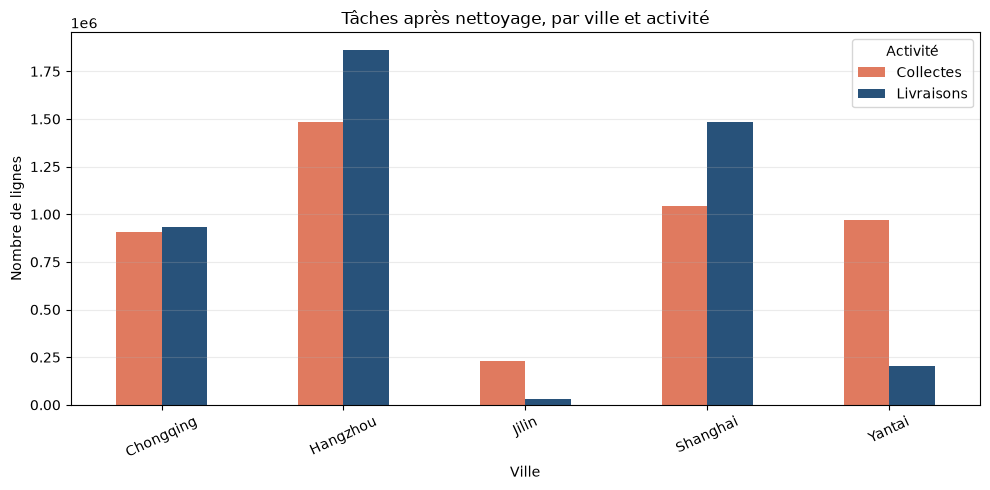

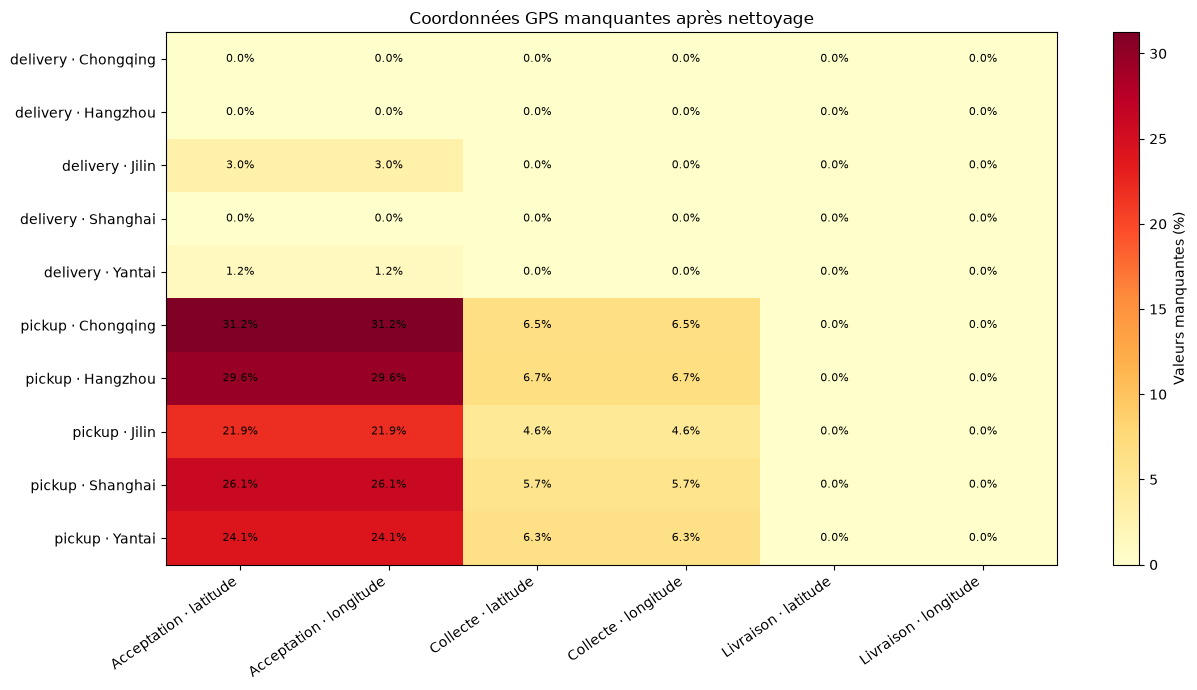

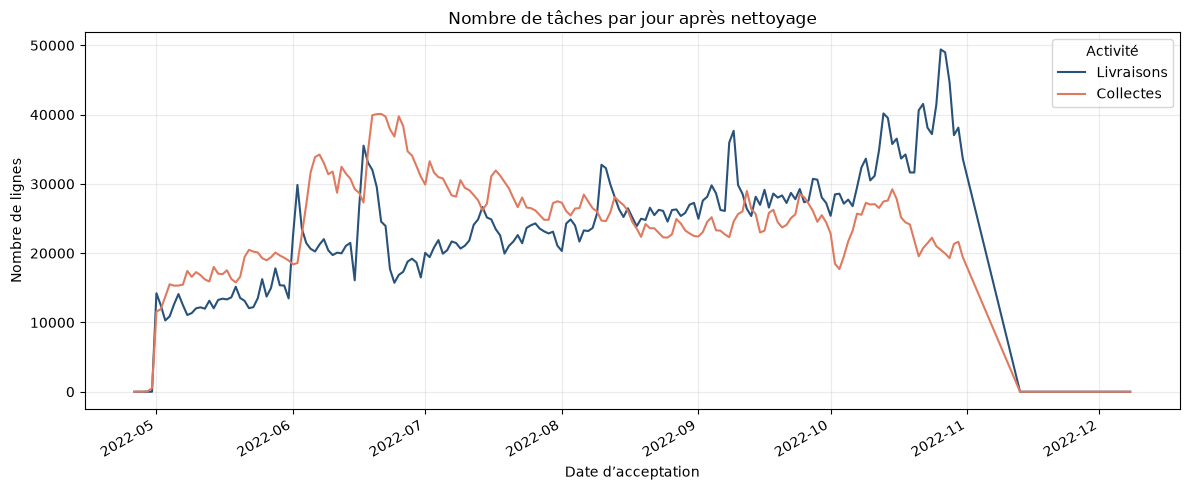

In [3]:
# 1. Volumes exacts par ville et type d'activité.
pivot = volumes.pivot(index='Ville', columns='Type', values='Lignes').fillna(0)
pivot = pivot.reindex(['Chongqing', 'Hangzhou', 'Jilin', 'Shanghai', 'Yantai'])
ax = pivot[['pickup', 'delivery']].plot(kind='bar', figsize=(10, 5), color=['#e07a5f', '#28527a'])
ax.set(title='Tâches après nettoyage, par ville et activité', xlabel='Ville', ylabel='Nombre de lignes')
ax.legend(['Collectes', 'Livraisons'], title='Activité')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.get_figure().tight_layout()
ax.get_figure().savefig(report_dir / 'volume_par_ville_nettoye.png', dpi=180, bbox_inches='tight')
plt.show()

# 2. Taux de coordonnées GPS manquantes, exacts sur les fichiers traités.
gps_table['Libellé'] = gps_table['Champ'].str.replace('_gps_lng', ' · longitude', regex=False).str.replace('_gps_lat', ' · latitude', regex=False).str.replace('accept', 'Acceptation').str.replace('pickup', 'Collecte').str.replace('delivery', 'Livraison')
gps_table['Groupe'] = gps_table['Type'] + ' · ' + gps_table['Ville']
gps_matrix = gps_table.pivot(index='Groupe', columns='Libellé', values='Taux manquant (%)').fillna(0)
fig, ax = plt.subplots(figsize=(13, 7))
image = ax.imshow(gps_matrix.to_numpy(), aspect='auto', cmap='YlOrRd', vmin=0, vmax=max(10, gps_matrix.to_numpy().max()))
ax.set_title('Coordonnées GPS manquantes après nettoyage')
ax.set_yticks(range(len(gps_matrix.index)), labels=gps_matrix.index)
ax.set_xticks(range(len(gps_matrix.columns)), labels=gps_matrix.columns, rotation=35, ha='right')
for i in range(gps_matrix.shape[0]):
    for j in range(gps_matrix.shape[1]):
        ax.text(j, i, f'{gps_matrix.iloc[i, j]:.1f}%', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Valeurs manquantes (%)')
fig.tight_layout()
fig.savefig(report_dir / 'taux_gps_manquants_nettoye.png', dpi=180, bbox_inches='tight')
plt.show()

# 3. Volume quotidien calculé avec accept_time, après nettoyage.
daily_frames = []
for kind, counts in daily_counts.items():
    daily_frames.append(pd.Series(counts, name=kind, dtype='int64'))
daily = pd.concat(daily_frames, axis=1).fillna(0).sort_index()
daily.index = pd.to_datetime(daily.index)
daily.to_csv(report_dir / 'volumes_quotidiens.csv', index_label='Date')
ax = daily.plot(figsize=(12, 5), color={'delivery': '#28527a', 'pickup': '#e07a5f'})
ax.set(title='Nombre de tâches par jour après nettoyage', xlabel='Date d’acceptation', ylabel='Nombre de lignes')
ax.legend(['Livraisons', 'Collectes'], title='Activité')
ax.grid(alpha=.25)
ax.get_figure().tight_layout()
ax.get_figure().savefig(report_dir / 'volume_temporel_nettoye.png', dpi=180, bbox_inches='tight')
plt.show()

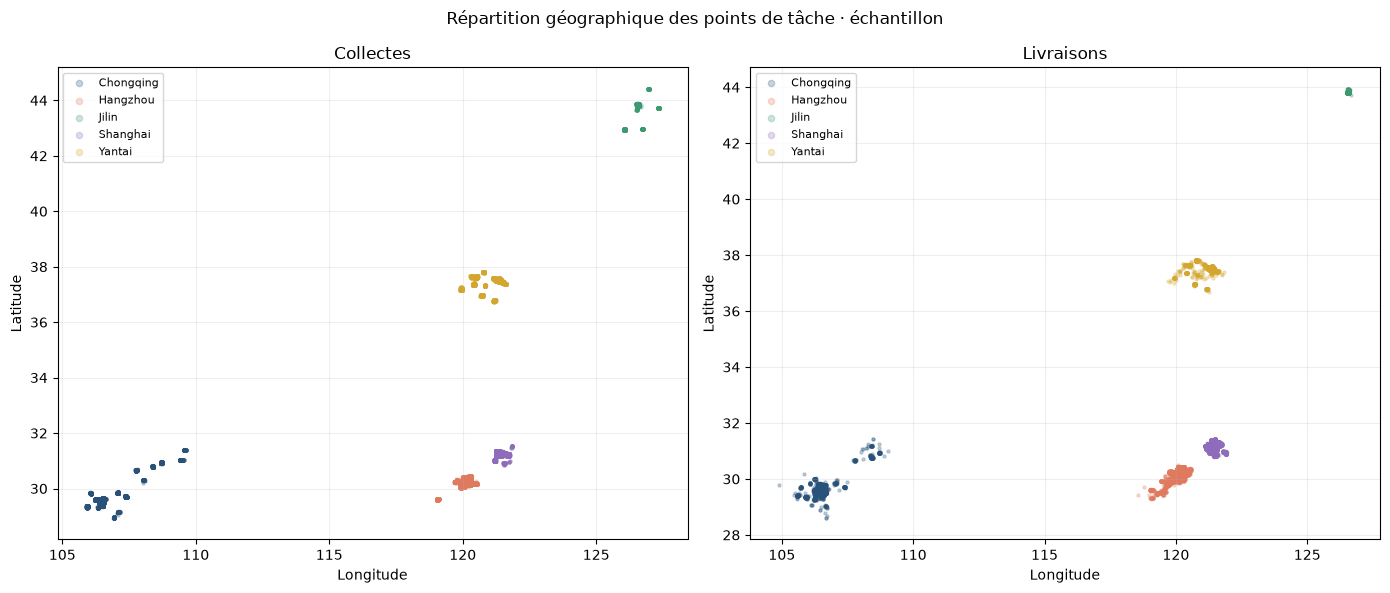

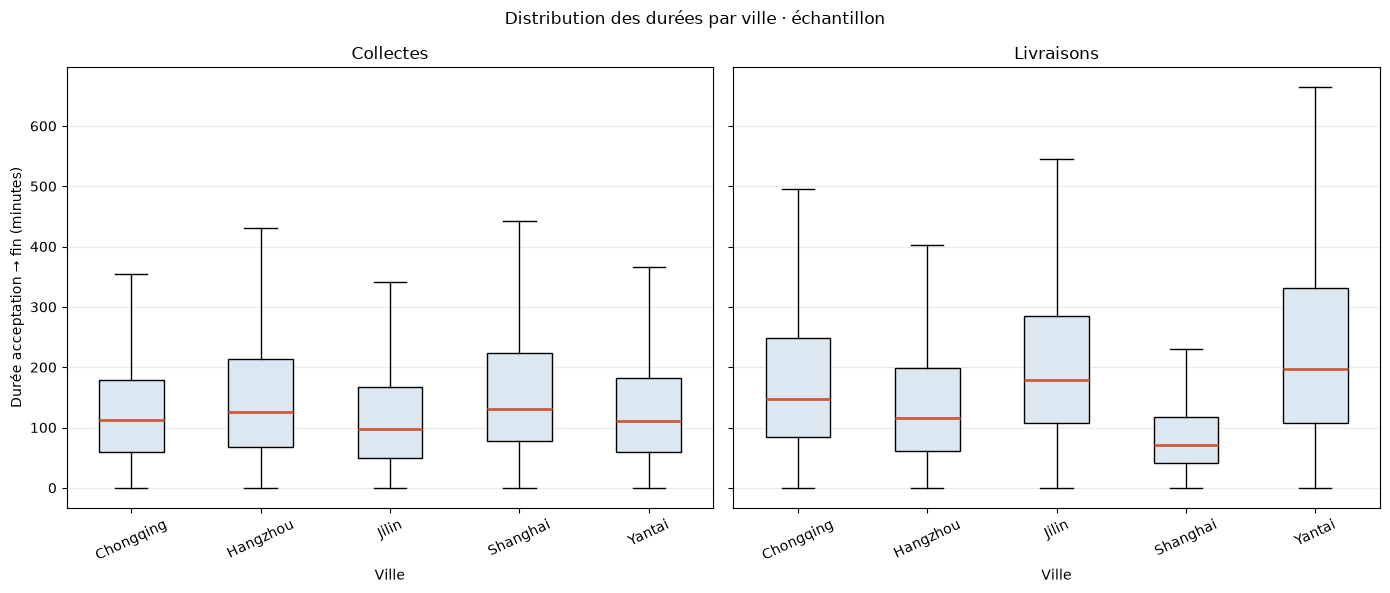

In [4]:
# 4. Répartition des points de tâche, sur un échantillon reproductible.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
city_colors = {'Chongqing': '#28527a', 'Hangzhou': '#e07a5f', 'Jilin': '#3d9970', 'Shanghai': '#8e6cbb', 'Yantai': '#d4a72c'}
for ax, kind in zip(axes, ['pickup', 'delivery']):
    subset = geo_data[geo_data['type'] == kind]
    for city, points in subset.groupby('ville'):
        ax.scatter(points['lng'], points['lat'], s=5, alpha=.25, label=city, color=city_colors.get(city))
    ax.set(title='Collectes' if kind == 'pickup' else 'Livraisons', xlabel='Longitude', ylabel='Latitude')
    ax.grid(alpha=.2)
    ax.legend(markerscale=2, fontsize=8)
fig.suptitle('Répartition géographique des points de tâche · échantillon')
fig.tight_layout()
fig.savefig(report_dir / 'repartition_geographique_nettoyee.png', dpi=180, bbox_inches='tight')
plt.show()

# 5. Distribution des durées acceptation → fin de tâche, sur l'échantillon.
order = ['Chongqing', 'Hangzhou', 'Jilin', 'Shanghai', 'Yantai']
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, kind in zip(axes, ['pickup', 'delivery']):
    groups = [duration_data.loc[(duration_data['type'] == kind) & (duration_data['ville'] == city), 'durée (min)'].to_numpy() for city in order]
    ax.boxplot(groups, tick_labels=order, showfliers=False, patch_artist=True,
               boxprops={'facecolor': '#dce8f1'}, medianprops={'color': '#d05a3a', 'linewidth': 2})
    ax.set(title='Collectes' if kind == 'pickup' else 'Livraisons', xlabel='Ville')
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=.25)
axes[0].set_ylabel('Durée acceptation → fin (minutes)')
fig.suptitle('Distribution des durées par ville · échantillon')
fig.tight_layout()
fig.savefig(report_dir / 'durees_par_ville_nettoyees.png', dpi=180, bbox_inches='tight')
plt.show()
duration_data.groupby(['type', 'ville'])['durée (min)'].agg(
    effectif='count', médiane='median', q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75)
).reset_index().to_csv(report_dir / 'resume_durees_echantillon.csv', index=False)

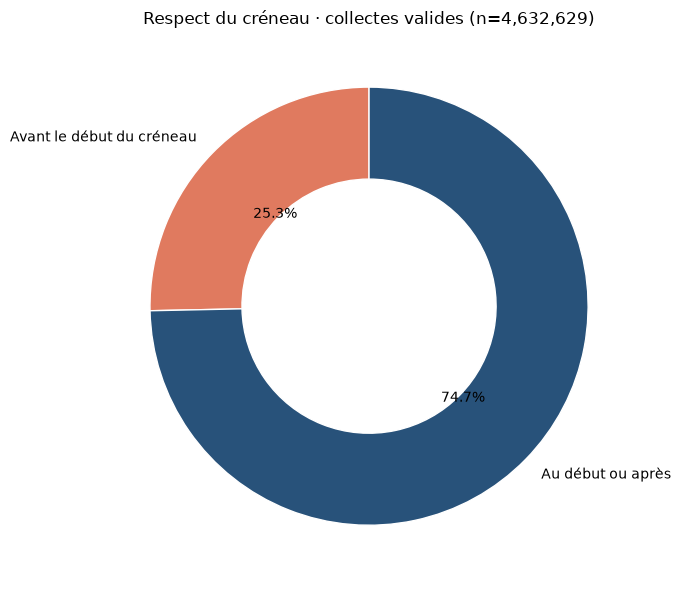

Figures et tableaux enregistrés dans : /home/yourix/Documents/PROJECTS/IOT/delivery-car/reports/etat_datasets_nettoye


In [5]:
# 6. Respect du créneau des collectes, calculé sur toutes les tâches valides.
slot_total = slot_counts[0] + slot_counts[1]
if slot_total:
    fig, ax = plt.subplots(figsize=(7, 6))
    values = [slot_counts[0], slot_counts[1]]
    labels = ['Avant le début du créneau', 'Au début ou après']
    ax.pie(values, labels=labels, autopct='%1.1f%%', startangle=90,
           colors=['#e07a5f', '#28527a'], wedgeprops={'width': .42, 'edgecolor': 'white'})
    ax.set_title(f'Respect du créneau · collectes valides (n={slot_total:,})')
    fig.tight_layout()
    fig.savefig(report_dir / 'respect_creneau_collectes.png', dpi=180, bbox_inches='tight')
    plt.show()
else:
    print('Aucune collecte avec heure de fin et début de créneau valides.')

print(f'Figures et tableaux enregistrés dans : {report_dir}')